<a href="https://colab.research.google.com/github/Ravi-ranjan1801/Data-Warehousing-Mining-Lab/blob/main/DWM_Lab_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Lab - 07 (OLAP Operations)**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import io
import os

from google.colab import files

uploaded = files.upload()

zip_name = next(iter(uploaded))

DATA_DIR = "/content/dwm_data"

os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as z:
    z.extractall(DATA_DIR)

print("Files extracted successfully!")

print(os.listdir(DATA_DIR))

Saving DWM_Practical_Datasets.zip to DWM_Practical_Datasets.zip
Files extracted successfully!
['08_classification_regression_models_cv_ann.csv', '06_entropy_information_gain_gini.csv', '02_normalization_discretization_students.csv', '03_pca_attribute_selection_students.csv', 'README_2_Hour_Lab_Instructions.txt', '05_apriori_market_basket.csv', '10_text_mining_documents.csv', '07_linear_regression_houses.csv', '09_clustering_kmeans_kmedoids.csv', '01_missing_values_patient_dataset.csv', '04_olap_sales_dataset.csv']


In [3]:
file_path = os.path.join(
    DATA_DIR,
    "04_olap_sales_dataset.csv"
)

df = pd.read_csv(file_path)

df['Date'] = pd.to_datetime(df['Date'])

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (120, 12)


,Order_ID,Date,Year,Quarter,Month,Region,City,Product,Category,Quantity,Unit_Price,Revenue
0,O0001,2025-07-25,2025,3,7,East,Delhi,Keyboard,Accessory,3,1800,5400
1,O0002,2025-01-24,2025,1,1,West,Ujjain,Phone,Mobile,7,22000,154000
2,O0003,2025-10-17,2025,4,10,North,Jabalpur,Keyboard,Accessory,4,1800,7200
3,O0004,2025-11-13,2025,4,11,South,Jabalpur,Keyboard,Accessory,1,1800,1800
4,O0005,2025-05-11,2025,2,5,North,Ujjain,Keyboard,Accessory,7,1800,12600



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order_ID    120 non-null    object        
 1   Date        120 non-null    datetime64[ns]
 2   Year        120 non-null    int64         
 3   Quarter     120 non-null    int64         
 4   Month       120 non-null    int64         
 5   Region      120 non-null    object        
 6   City        120 non-null    object        
 7   Product     120 non-null    object        
 8   Category    120 non-null    object        
 9   Quantity    120 non-null    int64         
 10  Unit_Price  120 non-null    int64         
 11  Revenue     120 non-null    int64         
dtypes: datetime64[ns](1), int64(6), object(5)
memory usage: 11.4+ KB

Missing Values:
Order_ID      0
Date          0
Year          0
Quarter       0
Month         0
Region        0
City          0
Pr

In [4]:
total_revenue = df['Revenue'].sum()

total_quantity = df['Quantity'].sum()

print("Total Sales Revenue:", total_revenue)

print("Total Quantity Sold:", total_quantity)

Total Sales Revenue: 10061600
Total Quantity Sold: 489


In [5]:
yearly_sales = df.groupby('Year').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum')
)

display(yearly_sales)

,Total_Revenue,Total_Quantity
Year,,
2025,10061600,489


In [6]:
region_sales = df.groupby('Region').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

display(region_sales)

,Region,Total_Revenue,Total_Quantity
0,East,2145600,127
1,North,1792400,99
2,South,4283600,153
3,West,1840000,110


In [7]:
region_category = df.groupby(
    ['Region', 'Category']
).agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

display(region_category)

,Region,Category,Total_Revenue,Total_Quantity
0,East,Accessory,66600,37
1,East,Computer,1371000,54
2,East,Mobile,708000,36
3,North,Accessory,50400,28
4,North,Computer,968000,34
5,North,Mobile,774000,37
6,South,Accessory,48600,27
7,South,Computer,3543000,92
8,South,Mobile,692000,34
9,West,Accessory,54000,30


In [8]:
drill_down = df.groupby(
    ['Year', 'Quarter', 'Month']
).agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

display(drill_down)

,Year,Quarter,Month,Total_Revenue,Total_Quantity
0,2025,1,1,930800,47
1,2025,1,2,779000,54
2,2025,1,3,561400,34
3,2025,2,4,884000,24
4,2025,2,5,1591800,64
5,2025,2,6,190400,16
6,2025,3,7,242400,33
7,2025,3,8,1079200,32
8,2025,3,9,848800,53
9,2025,4,10,534600,27


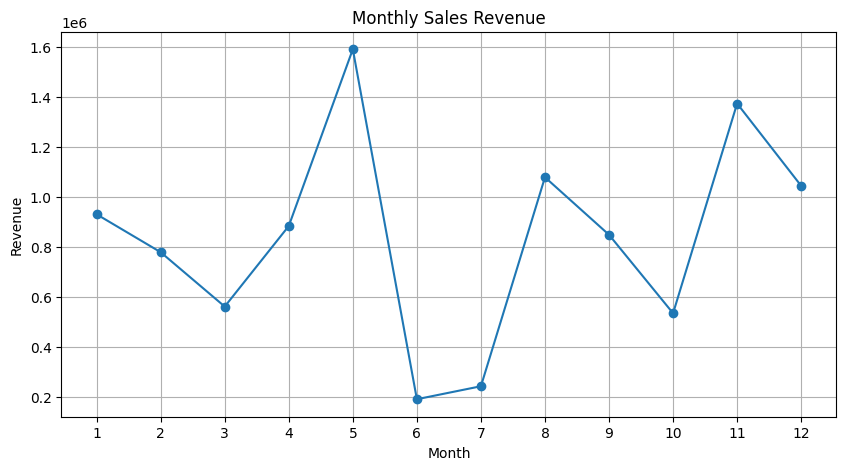

In [9]:
monthly_sales = df.groupby('Month')['Revenue'].sum()

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Sales Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue')

plt.xticks(range(1, 13))

plt.grid()
plt.show()

In [10]:
east_sales = df[df['Region'] == 'East']

print("Sales Data for East Region:")

display(east_sales)

print("\nTotal Revenue in East Region:")

print(east_sales['Revenue'].sum())

Sales Data for East Region:


,Order_ID,Date,Year,Quarter,Month,Region,City,Product,Category,Quantity,Unit_Price,Revenue
0,O0001,2025-07-25,2025,3,7,East,Delhi,Keyboard,Accessory,3,1800,5400
5,O0006,2025-11-11,2025,4,11,East,Jabalpur,Tablet,Mobile,3,18000,54000
7,O0008,2025-04-27,2025,2,4,East,Ujjain,Phone,Mobile,2,22000,44000
8,O0009,2025-08-01,2025,3,8,East,Ujjain,Monitor,Computer,5,14000,70000
9,O0010,2025-09-28,2025,3,9,East,Ujjain,Tablet,Mobile,4,18000,72000
18,O0019,2025-07-10,2025,3,7,East,Delhi,Monitor,Computer,7,14000,98000
24,O0025,2025-01-03,2025,1,1,East,Ujjain,Monitor,Computer,2,14000,28000
25,O0026,2025-01-14,2025,1,1,East,Delhi,Monitor,Computer,3,14000,42000
32,O0033,2025-04-06,2025,2,4,East,Jabalpur,Tablet,Mobile,2,18000,36000
33,O0034,2025-11-11,2025,4,11,East,Gwalior,Phone,Mobile,4,22000,88000



Total Revenue in East Region:
2145600


In [11]:
year_2025 = df[df['Year'] == 2025]

display(year_2025)

,Order_ID,Date,Year,Quarter,Month,Region,City,Product,Category,Quantity,Unit_Price,Revenue
0,O0001,2025-07-25,2025,3,7,East,Delhi,Keyboard,Accessory,3,1800,5400
1,O0002,2025-01-24,2025,1,1,West,Ujjain,Phone,Mobile,7,22000,154000
2,O0003,2025-10-17,2025,4,10,North,Jabalpur,Keyboard,Accessory,4,1800,7200
3,O0004,2025-11-13,2025,4,11,South,Jabalpur,Keyboard,Accessory,1,1800,1800
4,O0005,2025-05-11,2025,2,5,North,Ujjain,Keyboard,Accessory,7,1800,12600
...,...,...,...,...,...,...,...,...,...,...,...,...
115,O0116,2025-03-28,2025,1,3,North,Indore,Laptop,Computer,4,55000,220000
116,O0117,2025-11-27,2025,4,11,South,Indore,Monitor,Computer,4,14000,56000
117,O0118,2025-12-13,2025,4,12,South,Jabalpur,Phone,Mobile,1,22000,22000
118,O0119,2025-02-08,2025,1,2,South,Delhi,Keyboard,Accessory,7,1800,12600


In [12]:
selected_regions = ['North', 'West']

selected_products = ['Laptop', 'Phone']

dice_data = df[
    (df['Region'].isin(selected_regions)) &
    (df['Product'].isin(selected_products))
]

display(dice_data)

print("\nTotal Revenue:", dice_data['Revenue'].sum())

print("Total Quantity:", dice_data['Quantity'].sum())

,Order_ID,Date,Year,Quarter,Month,Region,City,Product,Category,Quantity,Unit_Price,Revenue
1,O0002,2025-01-24,2025,1,1,West,Ujjain,Phone,Mobile,7,22000,154000
16,O0017,2025-02-10,2025,1,2,North,Delhi,Phone,Mobile,5,22000,110000
17,O0018,2025-03-10,2025,1,3,West,Jabalpur,Phone,Mobile,6,22000,132000
29,O0030,2025-01-24,2025,1,1,West,Bhopal,Phone,Mobile,7,22000,154000
30,O0031,2025-11-18,2025,4,11,West,Indore,Phone,Mobile,7,22000,154000
36,O0037,2025-05-11,2025,2,5,North,Indore,Phone,Mobile,1,22000,22000
46,O0047,2025-12-20,2025,4,12,North,Indore,Phone,Mobile,6,22000,132000
64,O0065,2025-08-18,2025,3,8,West,Jabalpur,Phone,Mobile,1,22000,22000
70,O0071,2025-08-04,2025,3,8,North,Jabalpur,Laptop,Computer,4,55000,220000
73,O0074,2025-09-30,2025,3,9,West,Bhopal,Phone,Mobile,7,22000,154000



Total Revenue: 2618000
Total Quantity: 92


In [13]:
pivot_table = pd.pivot_table(
    df,
    values='Revenue',
    index='Region',
    columns='Category',
    aggfunc='sum',
    fill_value=0,
    margins=True
)

display(pivot_table)

Category,Accessory,Computer,Mobile,All
Region,,,,
East,66600,1371000,708000,2145600
North,50400,968000,774000,1792400
South,48600,3543000,692000,4283600
West,54000,554000,1232000,1840000
All,219600,6436000,3406000,10061600


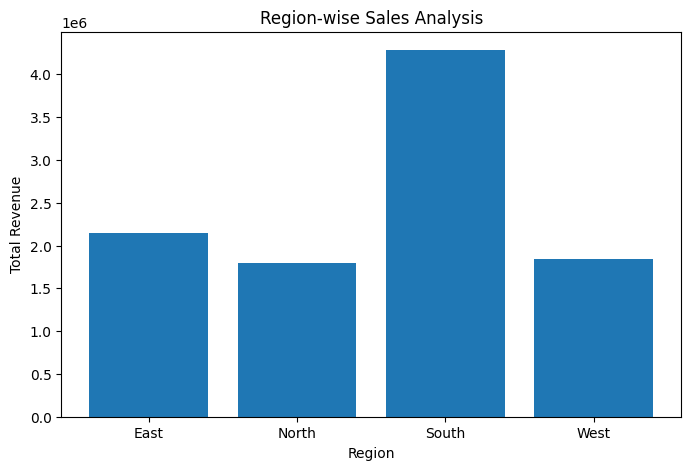

In [14]:
plt.figure(figsize=(8, 5))

plt.bar(
    region_sales['Region'],
    region_sales['Total_Revenue']
)

plt.xlabel('Region')
plt.ylabel('Total Revenue')

plt.title('Region-wise Sales Analysis')

plt.show()

## **Interpretation**
Observations:
1. The total sales revenue is 10,061,600, with 489 units sold.
2. South region generates the highest revenue.
3. Computer category contributes the highest revenue compared to Mobile and Accessory.
4. Roll-up provides summarized sales information, whereas drill-down provides more detailed information.
5. Slice selects data based on one dimension, while Dice selects data based on multiple dimensions.
6. Pivot tables help compare sales across different dimensions.